# P2 round 1: width comparison

Six predeclared dataset/width cells, one training seed (42). Kryptonite-20 width 128 reuses the existing pilot; five new CPU runs use the same numerical training core. The immutable declaration is `member_c/configs/p2_round1/manifest.json`. These are selected **validation** results, not test or hidden accuracy. A single seed cannot establish a stable architecture ranking or training variance.

Rebuild the checked CSV with `.venv/bin/python -m member_c.summarize_round1`. Exact training commands, run metadata, configurations, source snapshots, timings and logs accompany the run directories. Do not rerun training into an existing directory.

**Display:** Run all cells to plot directly below the code with `plt.show()`. No PDF or image files are exported. Matplotlib renders mathematical labels without external LaTeX.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'common.py').is_file())
assert Path(sys.prefix).resolve() == (root / '.venv').resolve()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from member_c.summarize_round1 import collect
manifest = json.loads((root / 'member_c/configs/p2_round1/manifest.json').read_text())
rows = collect(manifest)
header = '| Dataset | Width | Train accuracy | Validation accuracy | Gap (pp) | Parameters | Best / stopped epoch | Loop time (s) |\n|---|---|---:|---:|---:|---:|---|---:|'
lines = [f"| {r['dataset']} | {r['hidden_sizes']} | {r['train_accuracy']:.2%} | {r['validation_accuracy']:.2%} | {r['gap_percentage_points']:.2f} | {r['parameter_count']:,} | {r['best_epoch']} / {r['epochs_run']} | {r['training_seconds']:.2f} |" for r in rows]
display(Markdown(header + '\n' + '\n'.join(lines)))


| Dataset | Width | Train accuracy | Validation accuracy | Gap (pp) | Parameters | Best / stopped epoch | Loop time (s) |
|---|---|---:|---:|---:|---:|---|---:|
| 20 | 128x128 | 99.20% | 89.58% | 9.62 | 19,329 | 73 / 93 | 2.78 |
| 20 | 256x256 | 99.48% | 91.38% | 8.10 | 71,425 | 39 / 59 | 2.40 |
| 30 | 128x128 | 98.43% | 90.83% | 7.60 | 20,609 | 46 / 66 | 3.39 |
| 30 | 256x256 | 99.94% | 91.27% | 8.66 | 73,985 | 34 / 54 | 3.46 |
| 40 | 128x128 | 96.67% | 93.56% | 3.11 | 21,889 | 25 / 45 | 3.65 |
| 40 | 256x256 | 97.42% | 93.19% | 4.23 | 76,545 | 18 / 38 | 3.93 |

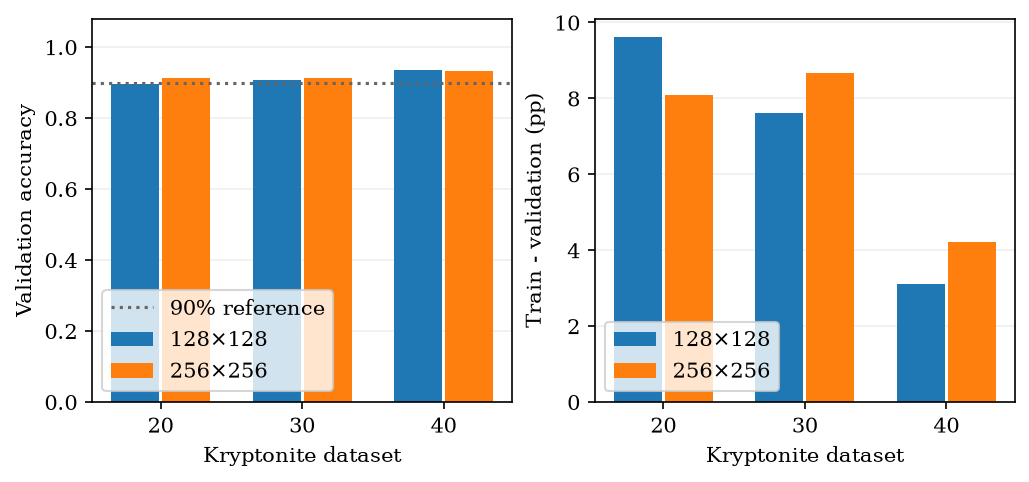

In [2]:
# Plot directly in the notebook; no file export or external LaTeX required.
plt.rcParams.update({
    'text.usetex': False, 'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 10.1, 'axes.labelsize': 10.1, 'xtick.labelsize': 10.1,
    'ytick.labelsize': 10.1, 'legend.fontsize': 10.1, 'figure.titlesize': 10.1,
    'axes.unicode_minus': True, 'figure.dpi': 150,
})
fig, axes = plt.subplots(1, 2, figsize=(6.75, 3.1), constrained_layout=True)
x = np.arange(3)
for offset, width, color in [(-0.18, '128x128', 'tab:blue'), (0.18, '256x256', 'tab:orange')]:
    selected = [next(r for r in rows if r['dataset']==dataset and r['hidden_sizes']==width) for dataset in ['20','30','40']]
    bars = axes[0].bar(x+offset, [r['validation_accuracy'] for r in selected], width=0.34, label=width.replace('x', r'$\times$'), color=color)
    axes[1].bar(x+offset, [r['gap_percentage_points'] for r in selected], width=0.34, label=width.replace('x', r'$\times$'), color=color)
axes[0].axhline(0.9, color='0.4', linestyle=':', label=r'90% reference')
axes[0].set(ylabel='Validation accuracy', ylim=(0, 1.08))
axes[1].set(ylabel='Train - validation (pp)')
for ax in axes:
    ax.set_xticks(x, ['20','30','40'])
    ax.set_xlabel('Kryptonite dataset')
    ax.legend(loc='lower left')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
plt.show()


**Figure.** Validation accuracy and training/validation gap at each model's selected checkpoint. Width is the intended comparison factor; depth, preprocessing, optimizer, learning rate, batch size, seed and stopping rules are fixed. Actual optimization steps and compute differ because of early stopping. The 90% line is a reference target: exceeding it on selected validation data does not establish hidden-set success. No error bars are shown because this round has only one training seed. Loop times include training, split scoring and writes, and exclude interpreter startup/data loading.
